<img src="https://github.com/vhxjaouen/HealthLabs-IMTA/blob/main/notebooks/IMTA.png?raw=1" alt="Logo IMT Atlantique" width="300"/>

##  **Data Heterogeneity in medical imaging**
### Case study : How to address data scarcity in Prostate MRI ?
### TAF DaSci - March 2026

Vincent.Jaouen@imt-atlantique.fr


In this lab, we will work with the **Prostate158** dataset (Mid-Axial slices).
We want to understand the impact of **training data size** and **augmentation** on segmentation performance.

**Dataset**:
*   Images: T2-weighted MRI slices of the prostate-
*   Labels: Prostate segmentation masks.

**Plan:**
1.  **Setup**: Load `prostate158` dataset and define a fixed validation split.
2.  **Part I (Scarcity)**: Train specific U-Nets on very small subsets (e.g., 5, 10, 20 images) without augmentation.
3.  **Part II (Augmentation)**: Repeat the training on the smallest subsets using extensive Data Augmentation.
4.  **Analysis**: Compare learning curves and final Dice scores.

In [1]:
# Setup for Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

import os
if IN_COLAB:
    print("Running on Google Colab. Setting up environment...")

    repo_name = "HealthLabs-IMTA"
    repo_url = "https://github.com/vhxjaouen/HealthLabs-IMTA.git"

    # Go to root if we appear to be in the repo's notebooks directory
    if os.path.basename(os.getcwd()) == "notebooks" and os.path.exists("../setup.py"):
        os.chdir("..")
        print("Moved to repository root.")

    # Check if we need to clone
    if not os.path.exists("setup.py"):
        if not os.path.exists(repo_name):
            print(f"Cloning {repo_name}...")
            !git clone {repo_url}

        # Move into the repo
        if os.path.exists(repo_name):
            os.chdir(repo_name)
            print(f"Changed directory to {os.getcwd()}")

    # Install package
    if os.path.exists("setup.py"):
        print("Installing package...")
        !pip install .
    else:
        print(f"Error: Could not find setup.py at {os.getcwd()}")
        print(f"Directory contents: {os.listdir(os.getcwd())}")

    # Move to notebooks directory for running the rest of the notebook
    if os.path.exists("notebooks"):
        os.chdir("notebooks")
        print(f"Working directory set to: {os.getcwd()}")

    print("Environment setup complete.")
else:
    print("Running locally.")

import torch
if torch.cuda.is_available():
    print(f"GPU is available: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No GPU detected. Training will be very slow.")

Running on Google Colab. Setting up environment...
Cloning HealthLabs-IMTA...
Cloning into 'HealthLabs-IMTA'...
remote: Enumerating objects: 3142, done.
remote: Counting objects: 100% (152/152), done.
remote: Compressing objects: 100% (122/122), done.
remote: Total 3142 (delta 47), reused 124 (delta 25), pack-reused 2990 (from 1)
Receiving objects: 100% (3142/3142), 130.43 MiB | 19.22 MiB/s, done.
Resolving deltas: 100% (189/189), done.
Updating files: 100% (3671/3671), done.
Changed directory to /content/HealthLabs-IMTA
Installing package...
Processing /content/HealthLabs-IMTA
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 82.7 MB/s eta 0:00:00
  Created wheel for healthlabs_imta: filename=healthlabs_imta-0.1.0-py3-none-any.whl size=12051 sha256=abc986af47fbb8b01db4a951785ac8466bdf2de68f9f5387ddcae3056bd273fa
  Stored in directory: /root/.cache/pip/wheels/98/60/4b/3112c3825fe5f71605d5018ca28c7bc936c0660aabcf2d572f
Successfully built hea

In [2]:
import sys, os
sys.path.append(os.path.abspath("..")) # Removed as we use the installed package now
import torch
import glob
import json
import numpy as np
import matplotlib.pyplot as plt
import yaml
from monai.data import CacheDataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityRangePercentilesd,
    RandFlipd, RandRotate90d, RandZoomd, RandShiftIntensityd, RandGaussianNoised,
    EnsureTyped, SpatialPadd, CenterSpatialCropd, Resized
)
from monai.utils import set_determinism

# Fix seed for reproducibility
set_determinism(seed=29200)

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


## 1. Data Loading

We will parse the `dataset.json` provided with the dataset to get image/label pairs.

In [3]:
# Configuration
data_dir = "../datasets/prostate158_MidAxial"
json_path = os.path.join(data_dir, "dataset.json")

# Load dataset.json
with open(json_path) as f:
    schema = json.load(f)

# Extract training paths (relative paths in JSON need to be joined with data_dir)
data_dicts = []
for entry in schema["training"]:
    # json entries: "./imagesTr/xxx.nii.gz"
    img_path = os.path.join(data_dir, entry["image"].replace("./", ""))
    lbl_path = os.path.join(data_dir, entry["label"].replace("./", ""))
    data_dicts.append({"image": img_path, "label": lbl_path})

print(f"Total available images: {len(data_dicts)}")

# Check one pair
print(f"Sample Image: {data_dicts[0]['image']}")

# Define Fixed Split (Last 30 for Validation)
val_size = 30
val_files = data_dicts[-val_size:]
train_pool = data_dicts[:-val_size]

print(f"Validation set size: {len(val_files)}")
print(f"Training pool size: {len(train_pool)}")

Total available images: 139
Sample Image: ../datasets/prostate158_MidAxial/imagesTr/020.nii.gz
Validation set size: 30
Training pool size: 109


Visualizing Sample 0:
Image: ../datasets/prostate158_MidAxial/imagesTr/020.nii.gz
Label: ../datasets/prostate158_MidAxial/labelsTr/020.nii.gz


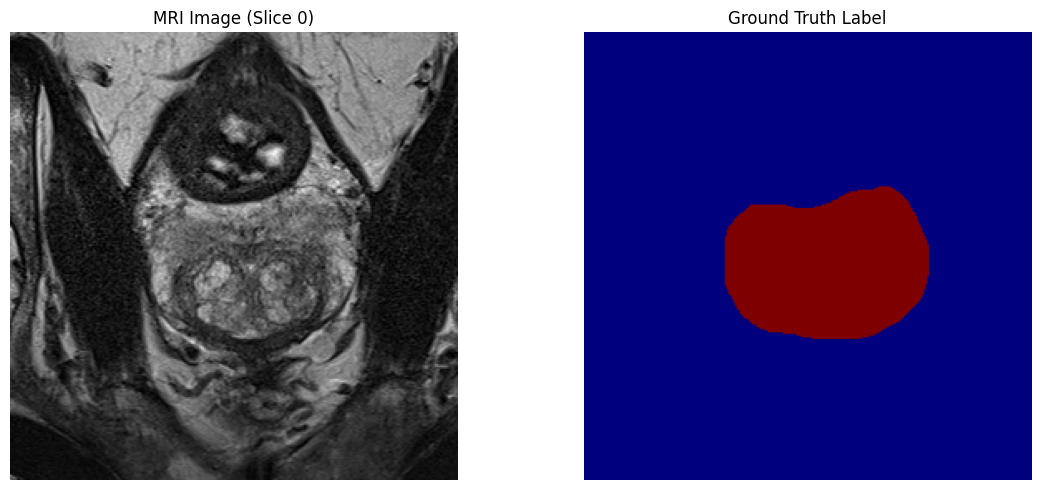

In [4]:
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

def visualize_dataset_sample(data_dicts, idx):
    if idx >= len(data_dicts):
        print(f"Index {idx} out of bounds (Max: {len(data_dicts)-1})")
        return

    sample = data_dicts[idx]
    img_path = sample["image"]
    lbl_path = sample["label"]

    print(f"Visualizing Sample {idx}:")
    print(f"Image: {img_path}")
    print(f"Label: {lbl_path}")

    # Load using Nibabel
    img_obj = nib.load(img_path)
    lbl_obj = nib.load(lbl_path)
    img_data = img_obj.get_fdata()
    lbl_data = lbl_obj.get_fdata()

    # Handle Dimensions (Show middle slice)
    if len(img_data.shape) == 3:
        mid_slice = img_data.shape[2] // 2
        img_show = img_data[:, :, mid_slice]
        lbl_show = lbl_data[:, :, mid_slice]
    else:
        img_show = img_data
        lbl_show = lbl_data

    # Plot
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img_show.T, cmap="gray", origin="lower")
    plt.title(f"MRI Image (Slice {mid_slice if len(img_data.shape)==3 else '2D'})")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(lbl_show.T, cmap="jet", origin="lower", alpha=1.0) # Mask only
    plt.title("Ground Truth Label")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# --- INTERACTIVE PART ---
# Change this index to explore different subjects!
# Try: 0, 10, 50, etc.
student_selected_index = 0

visualize_dataset_sample(data_dicts, student_selected_index)

### Observations: Data Heterogeneity

**Try changing the index above (e.g., set `student_selected_index = 10` and re-run).**

Observe the following:
*   **Intensity**: Do all images have similar brightness/contrast?
*   **Shape/Anatomy**: How does the prostate size vary?
*   **Position**: Is the prostate always centered?
*   **Resolution/FOV**: Are the image dimensions consistent?

This heterogeneity is a challenge for deep learning models, especially when training data is scarce.


## 2. Transforms Pipeline

We setup the MONAI transforms.
*   **Preprocessing**: Load, Channel First, Normalize Intensity (1st-99th percentile).
*   **Augmentation**: Flips, Rotation, Zoom, Intensity Shift (activated only if `augment=True`).

In [5]:
def get_transforms(augment=False):
    # Base Transforms
    transforms_list = [
        LoadImaged(keys=["image", "label"]),
        EnsureChannelFirstd(keys=["image", "label"], channel_dim=-1),
        Resized(keys=["image", "label"], spatial_size=(256, 256), mode=("bilinear", "nearest")),
        ScaleIntensityRangePercentilesd(
            keys="image", lower=1, upper=99,
            b_min=0.0, b_max=1.0, clip=True
        ),
        EnsureTyped(keys=["image", "label"]),
    ]

    # Augmentation
    if augment:
        transforms_list += [
            # Geometric
            # Vertical Flip (Axis 1) is anatomically more plausible than L/R or random rotation here
            RandFlipd(keys=["image", "label"], spatial_axis=1, prob=0.5),
            RandZoomd(keys=["image", "label"], min_zoom=0.9, max_zoom=1.1, mode=["area", "nearest"], prob=0.3),

            # Intensity
            RandShiftIntensityd(keys=["image"], offsets=0.1, prob=0.5),
            RandGaussianNoised(keys=["image"], prob=0.1, mean=0.0, std=0.05),
        ]

    return Compose(transforms_list)

## 3. Experiment Runner

We reuse the configuration from `segmentation.yaml` but override channel settings.

In [6]:
from healthlabs_imta.utils.training import train_segmentation
from healthlabs_imta.utils.model_utils import model_factory
from monai.losses import DiceCELoss
from monai.metrics import DiceMetric

# Load Config
import os
import healthlabs_imta
# Get the root directory of the cloned repository
repo_root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
config_path = os.path.join(repo_root_dir, "healthlabs_imta", "configs", "segmentation.yaml")

with open(config_path) as f:
    cfg = yaml.safe_load(f)

# Override config for this dataset
cfg["data"]["data_dir"] = data_dir
cfg["model"]["in_channels"] = 1   # Single channel MRI
cfg["model"]["out_channels"] = 1  # Binary segmentation
cfg["training"]["max_epochs"] = 30  # Set global default duration

def run_experiment(n_train_samples, augment, max_epochs=None):
    # Use config value if max_epochs not provided
    if max_epochs is None:
        max_epochs = cfg["training"]["max_epochs"]

    print(f"\n{'='*40}")
    print(f"Running Experiment: N={n_train_samples}, Augmentation={augment}, Epochs={max_epochs}")
    print(f"{'='*40}")

    # 1. Deterministic Subset
    train_subset = train_pool[:n_train_samples]

    # 2. Dataloaders
    train_ds = CacheDataset(
        data=train_subset,
        transform=get_transforms(augment=augment),
        cache_rate=1.0, num_workers=2
    )
    val_ds = CacheDataset(
        data=val_files,
        transform=get_transforms(augment=False),
        cache_rate=1.0, num_workers=2
    )

    train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=2)

    # 3. Model Setup
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model_factory(cfg["model"]).to(device)
    loss_fn = DiceCELoss(sigmoid=True, to_onehot_y=False)
    dice_metric = DiceMetric(include_background=True, reduction="mean")
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    # 4. Training
    history = train_segmentation(
        model, train_loader, val_loader,
        loss_fn, dice_metric, optimizer,
        device=device, max_epochs=max_epochs,
        overlay_fn=None # Disable plotting during loop
    )

    return history, model

## 4. Part I: Scarcity Impact (No Augmentation)

Train with **5, 10, 40** images.

In [7]:
results_no_aug = {}
sample_sizes = [100,50,20]

for n in sample_sizes:
    # We use 50 epochs for a fair comparison with the augmentation part
    (train_losses, val_dices, best_dice, weights), _ = run_experiment(n, augment=False, max_epochs=50)
    results_no_aug[n] = val_dices
    print(f"-> Final Best Dice (N={n}, No Aug): {best_dice:.4f}")


Running Experiment: N=100, Augmentation=False, Epochs=50


Loading dataset: 100%|██████████| 30/30 [00:00<00:00, 52.71it/s]


Training:   0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
results_aug = {}
aug_sample_sizes = [50,20]

for n in aug_sample_sizes:
    (train_losses, val_dices, best_dice, weights), _ = run_experiment(n, augment=True, max_epochs=50)
    results_aug[n] = val_dices
    print(f"-> Final Best Dice (N={n}, Aug): {best_dice:.4f}")


Running Experiment: N=50, Augmentation=True, Epochs=50


Training: 100%|██████████| 50/50 [02:03<00:00,  2.48s/it, loss=0.3453, dice=0.8769]


-> Final Best Dice (N=50, Aug): 0.8816

Running Experiment: N=20, Augmentation=True, Epochs=50


Training: 100%|██████████| 50/50 [01:40<00:00,  2.01s/it, loss=0.8904, dice=0.7971]

-> Final Best Dice (N=20, Aug): 0.8164


## 6. Analysis and Visualization

Compare the validation Dice curves.

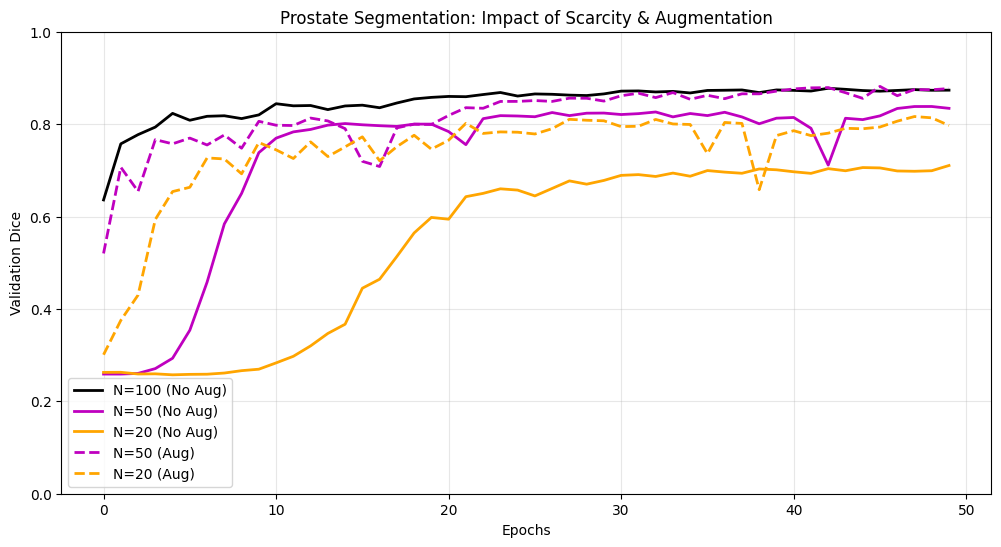

In [ ]:
plt.figure(figsize=(12, 6))

colors = {5: 'r', 10: 'g', 20: 'orange', 40: 'b', 50: 'm', 100: 'k'} # Adjusted colors

# Plot No Aug
for n, dices in results_no_aug.items():
    c = colors.get(n, 'gray') # Gray fallback if size not in dict
    plt.plot(dices, label=f'N={n} (No Aug)', color=c, linestyle='-', linewidth=2)

# Plot Aug
for n, dices in results_aug.items():
    c = colors.get(n, 'gray')
    plt.plot(dices, label=f'N={n} (Aug)', color=c, linestyle='--', linewidth=2)

plt.title("Prostate Segmentation: Impact of Scarcity & Augmentation")
plt.xlabel("Epochs")
plt.ylabel("Validation Dice")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 1.0)
plt.show()


## 7. Part III: Semi-Supervised Learning (Student-Teacher)

We simulate a scenario where we have **100 images** available, but only **50 are labeled**.
Can we leverage the 50 "unlabeled" images to improve the performance of a model trained on only 50 labeled examples?

**Strategy (Self-Training / Pseudo-Labeling):**
1.  **Train Teacher**: Use the 50 labeled images to train a model (Teacher).
2.  **Generate Pseudo-Labels**: Use the Teacher to predict segmentation masks for the 50 unlabeled images.
3.  **Train Student**: Train a new model (Student) on the **combined dataset** (50 Labeled + 50 Pseudo-Labeled).
4.  **Compare**: Student performance vs. Teacher (N=50) vs. Oracle (N=100 Labeled).


In [ ]:
from monai.transforms import SaveImaged
from monai.inferers import sliding_window_inference
import nibabel as nib
from monai.transforms import Resize
import shutil

# --- Experiment Configuration ---
n_labeled = 20       # Number of Ground Truth images to use
n_unlabeled = 70     # Number of additional images to pseudo-label
ssl_epochs = 50      # Training epochs for both Teacher and Student

print(f"Configuration: {n_labeled} Labeled, {n_unlabeled} Unlabeled, {ssl_epochs} Epochs")

Configuration: 20 Labeled, 70 Unlabeled, 50 Epochs


### 7.1. Train the Teacher
We start by training a "Teacher" model on the available labeled data (e.g., 50 images). This follows the standard supervised training procedure.

In [ ]:
print(f"--- Step 1: Training Teacher (N={n_labeled}) ---")

# Train Teacher using the existing experiment runner
# We store the results to compare later
(teacher_losses, teacher_dices, teacher_best_dice, teacher_weights), teacher_model = run_experiment(n_labeled, augment=True, max_epochs=ssl_epochs)

print(f"Teacher Best Validation Dice: {teacher_best_dice:.4f}")

--- Step 1: Training Teacher (N=20) ---

Running Experiment: N=20, Augmentation=True, Epochs=50


Loading dataset:   0%|          | 0/20 [00:00<?, ?it/s]

Training: 100%|██████████| 50/50 [01:30<00:00,  1.82s/it, loss=1.0365, dice=0.8076]

Teacher Best Validation Dice: 0.8178


### 7.2. Generate Pseudo-Labels
Now that we have a trained Teacher, we use it to predict segmentation masks for the "unlabeled" images. These predictions serve as "Pseudo-Labels" for the Student.

**Crucial Step**: We must ensure the generated pseudo-labels match the exact file structure (dimensions, spacing) of the original data so they can be loaded correctly later. This involves:
1. Predicting inference masks (which are usually 256x256 due to our transforms).
2. Resizing them *back* to the original image native resolution (e.g., 270x270).
3. Ensuring the NIfTI file format (3D vs 2D dimensions) matches the source inputs exactly.

In [ ]:
print(f"--- Step 2: Generating Pseudo-Labels for {n_unlabeled} images ---")

# 1. Prepare Teacher for Inference
teacher_model.load_state_dict(teacher_weights)
teacher_model.eval()

# 2. Select Unlabeled Data
# We select the images *immediately following* the labeled set in our training pool to simulate unlabeled data.
unlabeled_start = n_labeled
unlabeled_end = min(n_labeled + n_unlabeled, len(train_pool))
unlabeled_data = train_pool[unlabeled_start:unlabeled_end]

print(f"Generating labels for images {unlabeled_start} to {unlabeled_end}...")

# 3. Setup Output Directory
pseudo_label_dir = os.path.join(data_dir, "pseudo_labels")
if os.path.exists(pseudo_label_dir):
    shutil.rmtree(pseudo_label_dir) # Ensure a clean start
os.makedirs(pseudo_label_dir, exist_ok=True)

pseudo_labeled_data = []
infer_transforms = get_transforms(augment=False) # No augmentation for inference

# 4. Inference Loop
with torch.no_grad():
    for i, item in enumerate(unlabeled_data):
        # A. Load and Preprocess
        # Create a dictionary item to reuse the existing transform pipeline
        temp_item = {"image": item["image"], "label": item["image"]}
        input_data = infer_transforms(temp_item)
        input_tensor = input_data["image"].unsqueeze(0).to(torch.device("cuda" if torch.cuda.is_available() else "cpu"))

        # B. Predict (Teacher)
        outputs = teacher_model(input_tensor)
        outputs = torch.sigmoid(outputs)
        start_mask = (outputs > 0.5).float().cpu().numpy()[0, 0] # Threshold to binary mask

        # C. Post-process & Save
        # Resizing the prediction (256x256) back to the original native resolution (e.g., 270x270).
        orig_img = nib.load(item["image"])
        full_shape = orig_img.shape
        spatial_shape = full_shape[:2] if len(full_shape) == 3 else full_shape

        # Resize to native resolution
        resizer = Resize(spatial_size=spatial_shape, mode="nearest")
        mask_tensor_in = torch.from_numpy(start_mask).unsqueeze(0)
        mask_tensor_out = resizer(mask_tensor_in)
        final_mask = mask_tensor_out.squeeze(0).numpy()

        # Correct dimensions to match original NIfTI file (handle 2D vs 3D differences)
        if len(full_shape) == 3 and full_shape[2] == 1:
            final_mask = final_mask[:, :, np.newaxis]

        # Save pseudo-label as a NIfTI file
        pseudo_filename = f"pseudo_{os.path.basename(item['image'])}"
        pseudo_path = os.path.join(pseudo_label_dir, pseudo_filename)
        nib.save(nib.Nifti1Image(final_mask.astype(np.float32), orig_img.affine), pseudo_path)

        pseudo_labeled_data.append({"image": item["image"], "label": pseudo_path})

print(f"Generated {len(pseudo_labeled_data)} pseudo-labels in {pseudo_label_dir}")

--- Step 2: Generating Pseudo-Labels for 70 images ---
Generating labels for images 20 to 90...
Generated 70 pseudo-labels in ../datasets/prostate158_MidAxial/pseudo_labels


Comparing Pseudo-Label vs Truth for Sample 0
Image: ../datasets/prostate158_MidAxial/imagesTr/040.nii.gz


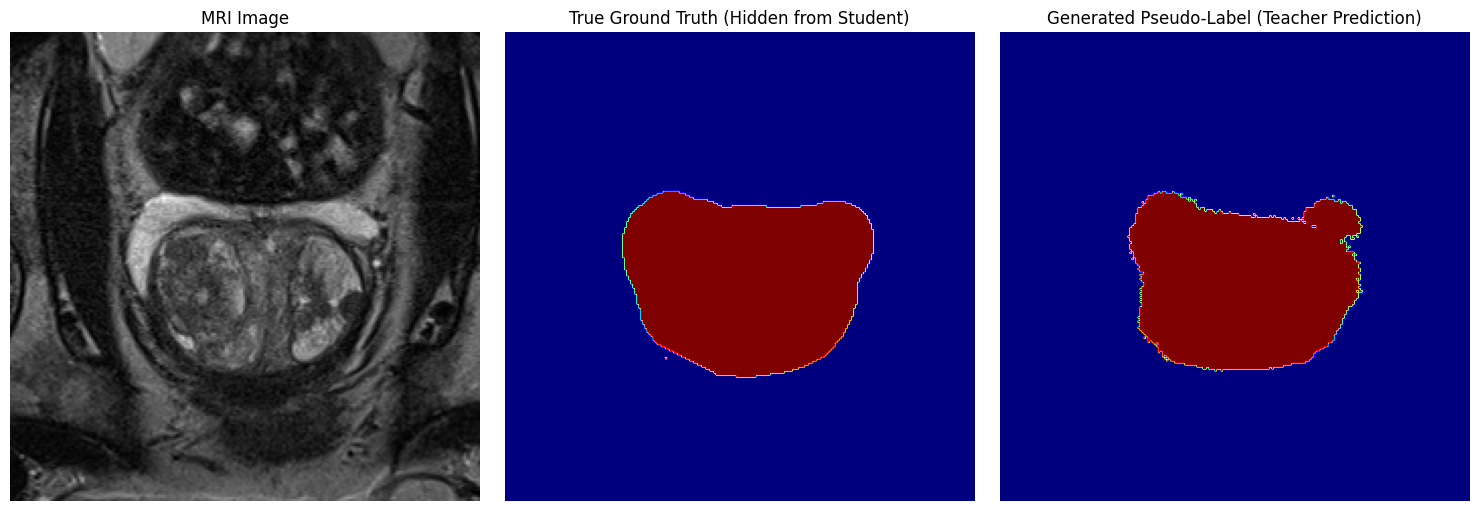

Comparing Pseudo-Label vs Truth for Sample 5
Image: ../datasets/prostate158_MidAxial/imagesTr/045.nii.gz


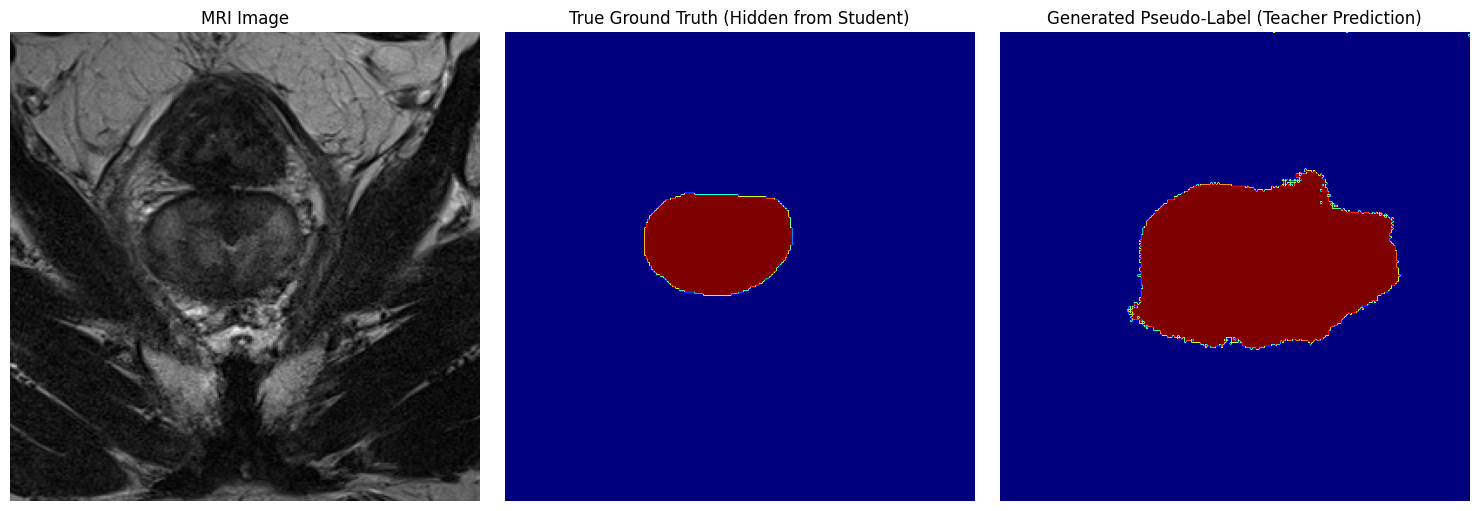

Comparing Pseudo-Label vs Truth for Sample 15
Image: ../datasets/prostate158_MidAxial/imagesTr/055.nii.gz


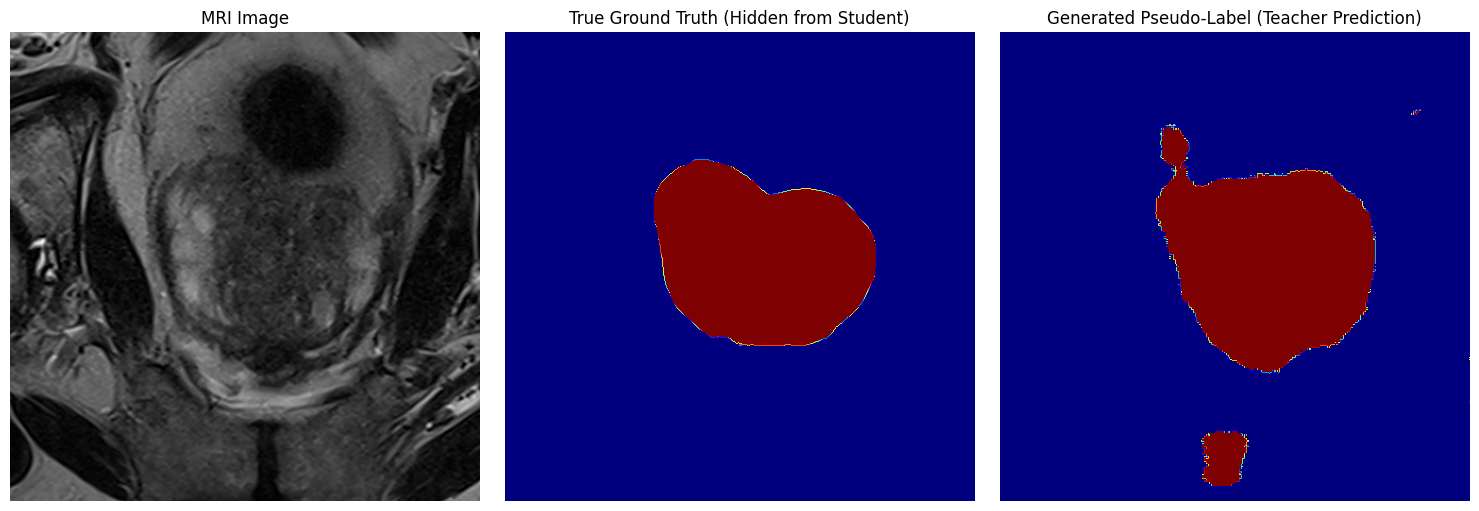

In [ ]:
# --- Visualization of Pseudo-Labels ---

def visualize_pseudo_quality(idx):
    if idx >= len(pseudo_labeled_data):
        print(f"Index {idx} out of bounds (Max: {len(pseudo_labeled_data)-1})")
        return

    # Get the item from the pseudo-labeled list
    pseudo_item = pseudo_labeled_data[idx]

    # Get the corresponding original item (which contains the TRUE Ground Truth)
    # We can retrieve it from 'unlabeled_data' since we iterated over it in order
    original_item = unlabeled_data[idx]

    img_path = pseudo_item["image"]
    pseudo_path = pseudo_item["label"]
    true_path = original_item["label"]

    # Load
    img = nib.load(img_path).get_fdata()
    pseudo = nib.load(pseudo_path).get_fdata()
    true_lbl = nib.load(true_path).get_fdata()

    # Slice Selection (Middle)
    if len(img.shape) == 3:
        sl = img.shape[2] // 2
        img_show = img[:, :, sl]
        pseudo_show = pseudo[:, :, sl]
        true_show = true_lbl[:, :, sl]
    else:
        img_show = img
        pseudo_show = pseudo
        true_show = true_lbl

    print(f"Comparing Pseudo-Label vs Truth for Sample {idx}")
    print(f"Image: {img_path}")

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img_show.T, cmap="gray", origin="lower")
    plt.title("MRI Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(true_show.T, cmap="jet", origin="lower", alpha=1.0)
    plt.title("True Ground Truth (Hidden from Student)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pseudo_show.T, cmap="jet", origin="lower", alpha=1.0)
    plt.title("Generated Pseudo-Label (Teacher Prediction)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Visualize a few examples to inspect quality
# Change indices to see more!
visualize_pseudo_quality(0)
visualize_pseudo_quality(5)
visualize_pseudo_quality(15)

### Observations: Quality of Pseudo-Labels

Pseudo-labels are predictions from the Teacher, so they might contain errors.

**Questions:**
*   Are the pseudo-labels perfect? Compare them with the "True Ground Truth" (middle vs right plot).
*   What happens if the Teacher makes a mistake? Will the Student learn this mistake?
*   Do you see any "noise" or irregular boundaries in the pseudo-labels?
*   Does the Teacher sometimes miss the whole organ?


### 7.3. Train the Student
The Student model is trained on the **Combined Dataset**:
1.  **Labeled Data**: The original Ground Truth examples.
2.  **Pseudo-Labeled Data**: The examples labeled by the Teacher.

We generally use **Strong Augmentation** for the student to encourage it to learn robust features and smooth out the noise from the imperfect pseudo-labels. In this lab, we simply reuse the `augment=True` pipeline.

In [ ]:
print(f"--- Step 3: Training Student (N={len(pseudo_labeled_data) + n_labeled}) ---")

# 1. Combine Datasets
labeled_data = train_pool[:n_labeled]
combined_data = labeled_data + pseudo_labeled_data

print(f"Student Data: {len(labeled_data)} Gold Standard + {len(pseudo_labeled_data)} Pseudo-Labeled")

# 2. Define Loaders
# Validation uses the SAME fixed validation set as always
val_ds_student = CacheDataset(
    data=val_files,
    transform=get_transforms(augment=False),
    cache_rate=1.0, num_workers=2
)
val_loader_student = DataLoader(val_ds_student, batch_size=1, shuffle=False, num_workers=2)

# Student Training Set
student_ds = CacheDataset(
    data=combined_data,
    transform=get_transforms(augment=True),
    cache_rate=1.0, num_workers=2
)
student_loader = DataLoader(student_ds, batch_size=4, shuffle=True, num_workers=2)

# 3. Initialize Student Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
student_model = model_factory(cfg["model"]).to(device)
loss_fn = DiceCELoss(sigmoid=True, to_onehot_y=False)
dice_metric = DiceMetric(include_background=True, reduction="mean")
optimizer = torch.optim.Adam(student_model.parameters(), lr=1e-3)

# 4. Train
(student_losses, student_dices, student_best_dice, student_weights) = train_segmentation(
    student_model, student_loader, val_loader_student,
    loss_fn, dice_metric, optimizer,
    device=device, max_epochs=ssl_epochs,
    overlay_fn=None
)

print(f"Student Best Validation Dice: {student_best_dice:.4f}")

--- Step 3: Training Student (N=90) ---
Student Data: 20 Gold Standard + 70 Pseudo-Labeled


Training: 100%|██████████| 50/50 [02:07<00:00,  2.55s/it, loss=0.1370, dice=0.8300]

Student Best Validation Dice: 0.8314


### 7.4. Analysis
We compare the Validation Dice curves of the Teacher (trained on only labeled data) and the Student (trained on labeled + pseudo-labeled data).

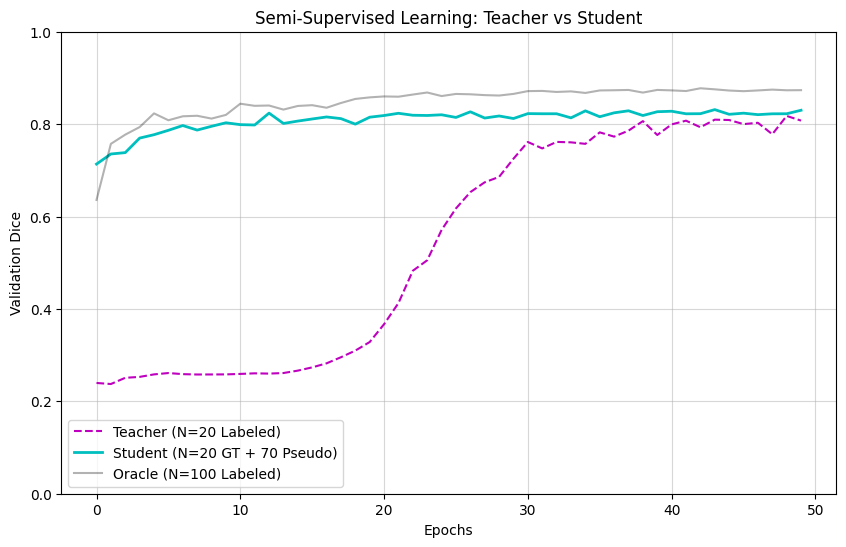

In [ ]:
plt.figure(figsize=(10, 6))

# Teacher
plt.plot(teacher_dices, label=f'Teacher (N={n_labeled} Labeled)', color='m', linestyle='--')

# Student
plt.plot(student_dices, label=f'Student (N={n_labeled} GT + {n_unlabeled} Pseudo)', color='c', linewidth=2)

# Oracle Baseline (if available from previous steps)
if 'results_aug' in globals() and 100 in results_aug:
     plt.plot(results_aug[100], label='Oracle (N=100 Labeled)', color='k', alpha=0.3)
elif 'results_no_aug' in globals() and 100 in results_no_aug:
     plt.plot(results_no_aug[100], label='Oracle (N=100 Labeled)', color='k', alpha=0.3)

plt.title("Semi-Supervised Learning: Teacher vs Student")
plt.xlabel("Epochs")
plt.ylabel("Validation Dice")
plt.legend()
plt.grid(True, alpha=0.5)
plt.ylim(0, 1.0)
plt.show()